# hBN bilayer: the bottom layer as an effective substrate

**Goal.** GW of the top layer with the bottom layer included only through its screening (Notes, Sec. 2.1). The
screened interaction in the layer obeys Eq. (19) of the notes,
$$
W = \tilde v + \tilde v\,\chi_0^{\mathrm{L}}\,W , \qquad \tilde v = v + v\,\chi^{\mathrm{S}}\,v ,
$$
with $\chi_0^{\mathrm{L}}$ the independent-particle response of the layer and $\chi^{\mathrm{S}}$ the (interacting)
response of the substrate. Both come from GW runs already done: the top layer alone (`ML_top_AA1`, `ML_top_AB`) and
the bottom layer alone (`ML_bot`), each computed in its exact position in the same cell.

Steps:
1. the Yambo screening databases: what they contain and how to read them;
2. moving a layer: the screening of the top layer from that of the bottom layer by translation and rotation;
3. $\tilde v$, the interaction dressed by the substrate, seen on the plane of the top layer;
4. $W$ of the top layer from Eq. (19), checked against the bilayer and written as a new screening database;
5. (next) GW of the top layer with this database, and comparison with the top-layer bands extracted from the explicit
   bilayer (`Projection_Analysis.ipynb`, `results/layer_projection.json`).

Data: the PPA screening databases of the GW runs at the converged parameters (`GW_Analysis.ipynb`: k = 18x18x1,
NGsBlkXp = 6 Ha, BndsRnXp = 200 for the layers, 212 for the bilayers, slab cutoff along z).

**Prototype.** The readers and the writer of the databases are written here to see how things work; once stable they
move to MPPI (user, 2026-11-17). MPPI is used for the rest (`YamboDftParser`, constants).

In [1]:
import os, shutil
import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset
from mppi.Parsers import YamboDftParser
from mppi.Utilities.Constants import HaToeV

MB = 'MB_analysis'
run = {'ML_bot': 'kpoints_18-nbnds_250-ML_bot', 'ML_top_AA1': 'kpoints_18-nbnds_250-ML_top_AA1',
       'ML_top_AB': 'kpoints_18-nbnds_250-ML_top_AB', 'AA1': 'kpoints_18-nbnds_400-AA1', 'AB': 'kpoints_18-nbnds_400-AB'}
screening = {s: os.path.join(MB, run[s], 'ndb_pp-ngsblkxp_6.0-bndsrnxp_' + ('200' if s.startswith('ML') else '212'))
             for s in run}
names = {'AA1': "AA'", 'AB': 'AB'}

## 1. The screening databases

A GW run in the plasmon-pole approximation (PPA) writes the screening in a folder (here
`ndb_pp-ngsblkxp_6.0-bndsrnxp_<n>`, shared by the runs that change only $\Sigma$):
- `ndb.pp`: header. `X_RL_vecs` = the $\mathbf G$ vectors of the response (the first 591 of the global list, 6 Ha),
  `HEAD_QPT` = the 37 $\mathbf q$ points of the IBZ, `X_PARS_1` = number of $\mathbf G$ and band range,
  `X_TDDFT_KERNEL` = `HARTREE` (RPA), `CUTOFF` = `slab z`.
- `ndb.pp_fragment_<iq>`, one per $\mathbf q$: `X_Q_<iq>`, a 591 x 591 complex matrix at two frequencies,
  `FREQ_sec_iq<iq>` = $0$ and $i\,27.2$ eV (the two points of the PPA fit). Stored in single precision; the netCDF
  array is the Fortran array $X(\mathbf G,\mathbf G',\omega)$ with the axes reversed, so the two $\mathbf G$ axes are
  transposed when read.

What $X$ is (Lumen source, `pol_function/X_redux.F`): Yambo builds $\chi_0$, solves the Dyson equation
$\chi = (1 - \chi_0 v)^{-1}\chi_0$ on this 591 x 591 block and stores the symmetrized form
$$
X_{\mathbf G\mathbf G'}(\mathbf q,\omega) = v^{1/2}_{\mathbf G}(\mathbf q)\,\chi_{\mathbf G\mathbf G'}(\mathbf q,\omega)\,
v^{1/2}_{\mathbf G'}(\mathbf q) = \varepsilon^{-1}_{\mathbf G\mathbf G'} - \delta_{\mathbf G\mathbf G'} ,
$$
with $v$ the Coulomb interaction truncated along $z$ (slab cutoff, $|z - z'| < c/2$). $\chi_0$ itself is not stored.
$v_{\mathbf G}(\mathbf q) = 4\pi/b^2_{\mathbf G}(\mathbf q)$, where $b$ = `CUT_BARE_QPG` of `ndb_rim_cutoff/ndb.cutoff`
($|\mathbf q + \mathbf G|$ modified by the cutoff, `coulomb/cutoff_slab.F`).

**Warning, `ndb.RIM_W`.** It is in the same folder, but it is not a property of the geometry only: Yambo builds it
from the $X$ of the screening database (`qp/QP_interpolate_W.F`), and reads it back if the header matches, without
checking $X$. With a modified screening database it must be recomputed: never copy it.

Readers (prototype):

In [2]:
def read_screening_header(folder):
    "Header of ndb.pp: G vectors and q points (iku = units of 2 pi/alat_i), number of G, bands, kernel, cutoff."
    d = Dataset(os.path.join(folder, 'ndb.pp'))
    text = lambda v: b''.join(np.ma.filled(d[v][:], b' ').ravel()).decode().strip()
    pars = np.array(d['X_PARS_1'][:])
    q0 = np.array(d['X_PARS_3'][3:6], dtype=float)       # 'Field direction': the small q used for q -> 0 (iq = 1)
    return {'q0': q0, 'G_iku': np.array(d['X_RL_vecs'][:], dtype=float).T, 'q_iku': np.array(d['HEAD_QPT'][:], dtype=float).T,
            'ng': int(pars[0]),
            'bands': (int(pars[1]), int(pars[2])), 'kernel': text('X_TDDFT_KERNEL'), 'cutoff': text('CUTOFF')}

def read_X(folder, iq):
    "X = v^1/2 chi v^1/2 = eps^-1 - 1 at the q point iq (1-based): array [frequency, G, G'] and frequencies (eV)."
    with Dataset(os.path.join(folder, 'ndb.pp_fragment_%d' % iq)) as f:
        x = np.array(f['X_Q_%d' % iq][:]).astype(float)
        w = np.array(f['FREQ_sec_iq%d' % iq][:]).astype(float)
    return np.transpose(x[..., 0] + 1j * x[..., 1], (0, 2, 1)), (w[:, 0] + 1j * w[:, 1]) * HaToeV

def read_bare_qpg(run_folder):
    "CUT_BARE_QPG of ndb.cutoff, shape (nq, nG): v_G(q) = 4 pi / bare_qpg^2."
    b = np.array(Dataset(os.path.join(run_folder, 'ndb_rim_cutoff', 'ndb.cutoff'))['CUT_BARE_QPG'][:])
    return (b[..., 0] + 1j * b[..., 1]).T.real

H = {s: read_screening_header(screening[s]) for s in run}
ng, nq = H['ML_bot']['ng'], len(H['ML_bot']['q_iku'])
bqpg = {s: read_bare_qpg(os.path.join(MB, run[s]))[:, :ng] for s in run}
save = {s: YamboDftParser(os.path.join(MB, run[s], 'SAVE', 'ns.db1'), verbose=False) for s in run}
freqs = {s: read_X(screening[s], 2)[1] for s in run}
print('%-11s %4s %9s %8s %7s %6s %6s %6s %6s %s' % ('system', 'ng', 'bands', 'kernel', 'cutoff', 'G', 'q', 'freq',
                                                     'v_cut', 'symmetries (as ML_bot)'))
for s in run:
    same = lambda a, b: 'same' if np.allclose(a, b, rtol=1e-6, atol=1e-8) else 'DIFF'
    S, S0 = np.array(save[s].syms), np.array(save['ML_bot'].syms)
    sym = '%d + TR' % len(S) if save[s].time_reversal else '%d' % len(S)
    sym += ', same' if (len(S) == len(S0) and np.allclose(S, S0, atol=1e-5)) else ', different'
    print('%-11s %4d %9s %8s %7s %6s %6s %6s %6s %s' % (s, H[s]['ng'], '%d-%d' % H[s]['bands'], H[s]['kernel'],
          H[s]['cutoff'], same(H[s]['G_iku'], H['ML_bot']['G_iku']), same(H[s]['q_iku'], H['ML_bot']['q_iku']),
          same(freqs[s], freqs['ML_bot']), same(bqpg[s], bqpg['ML_bot']), sym))
print('frequencies (eV):', np.round(freqs['ML_bot'], 3))

system        ng     bands   kernel  cutoff      G      q   freq  v_cut symmetries (as ML_bot)
ML_bot       591     1-200  HARTREE  slab z   same   same   same   same 12 + TR, same
ML_top_AA1   591     1-200  HARTREE  slab z   same   same   same   same 12 + TR, same
ML_top_AB    591     1-200  HARTREE  slab z   same   same   same   same 12 + TR, same
AA1          591     1-212  HARTREE  slab z   same   same   same   same 12, different
AB           591     1-212  HARTREE  slab z   same   same   same   same 12 + TR, same
frequencies (eV): [0. +0.j    0.+27.211j]


All the databases are on the same $\mathbf G$ block, $\mathbf q$ points, frequencies and truncated $v$, and the
three layers have the same symmetry operations in the same order (the AA' bilayer has its own 12, D3d: it is used only
for checks at the IBZ points). So the symmetrized matrices of different runs can be combined directly, without ever
writing $v$ explicitly. In particular, $\chi_0$, which is not stored, follows exactly from $X$ by inverting the Dyson
equation on the same block ($\varepsilon = (\varepsilon^{-1})^{-1}$, $\varepsilon = 1 - v\chi_0$):
$$
\tilde\chi_0 \equiv v^{1/2}\chi_0\,v^{1/2} = 1 - (1 + X)^{-1} .
$$

## 2. Moving a layer: the screening of the top layer from that of the bottom layer

The top layer is the bottom layer moved: by a translation in AB, by a rotation of 180 degrees about $z$ plus a
translation in AA' (B and N exchanged). If the screening of a moved layer can be obtained from that of the layer in one
position, a single layer calculation serves every position and orientation (in the same cell); here the computed
databases of `ML_top_AA1` and `ML_top_AB` are the test.

A layer moved by $\mathbf r \to R\mathbf r + \boldsymbol\tau$ ($R$ a rotation that maps the lattice onto itself,
$\boldsymbol\tau$ any translation, also along $z$) has $\chi'(\mathbf r, \mathbf r') = \chi(R^{-1}(\mathbf r -
\boldsymbol\tau), R^{-1}(\mathbf r' - \boldsymbol\tau))$. With the plane-wave expansion of the notes this gives
$$
\chi'_{\mathbf G\mathbf G'}(\mathbf q) = e^{-i(\mathbf G - \mathbf G')\cdot\boldsymbol\tau}\,
\chi_{R^{-1}\mathbf G,\,R^{-1}\mathbf G'}(R^{-1}\mathbf q)
$$
(the phases of $\mathbf q$ cancel). At $\mathbf q = 0$ (`iq` = 1) Yambo computes the head and the wings at a small
$\mathbf q_0$ along `LongDrXp` = [1,1,0] (`X_PARS_3`, "Field direction"), so there $\mathbf q_0$ is the vector that
$R$ acts on. The truncated $v_{\mathbf G}(\mathbf q)$ depends only on $|\mathbf q_\parallel +
\mathbf G_\parallel|$ and $G_z$, so it is unchanged by in-plane rotations and $X = v^{1/2}\chi v^{1/2}$ transforms in
the same way; the slab cutoff truncates $z - z'$, so a translation along $z$ is allowed (the whole system must stay
within $|z - z'| < c/2$).
- AB: $R = 1$, only the phase.
- AA': $R = C_{2z}$, so $R^{-1}\mathbf q = -\mathbf q$, which is not stored. Time reversal gives it (reciprocity,
  $\chi(\mathbf r, \mathbf r') = \chi(\mathbf r', \mathbf r)$): $\chi_{\mathbf G\mathbf G'}(-\mathbf q) =
  \chi_{-\mathbf G', -\mathbf G}(\mathbf q)$, hence
  $X'_{\mathbf G\mathbf G'}(\mathbf q) = e^{-i(\mathbf G - \mathbf G')\cdot\boldsymbol\tau}\,X_{\sigma\mathbf G',\,\sigma\mathbf G}(\mathbf q)$,
  with $\sigma\mathbf G = -C_{2z}^{-1}\mathbf G = (G_x, G_y, -G_z)$.
- A general $R$ with $R^{-1}\mathbf q \ne \pm\mathbf q$ needs $X$ outside the IBZ, from the symmetries of the layer
  ($X_{S\mathbf G, S\mathbf G'}(S\mathbf q) = X_{\mathbf G\mathbf G'}(\mathbf q)$ for a symmorphic $S$): not needed
  here, not implemented.

$\boldsymbol\tau$ maps the bottom B onto the top B (AB: $\boldsymbol\tau = \mathbf r_{\mathrm{top}} - \mathbf
r_{\mathrm{bot}}$; AA': $\boldsymbol\tau = \mathbf r_{\mathrm{top}} - C_{2z}\mathbf r_{\mathrm{bot}}$); the same
operation must map N onto N up to a lattice vector, checked below through the phases.

In [3]:
alat = np.array(save['ML_bot'].alat, dtype=float)        # yambo alat_i (bohr): G_cart = G_iku 2 pi / alat_i
G = H['ML_bot']['G_iku'] * 2 * np.pi / alat
q = H['ML_bot']['q_iku'] * 2 * np.pi / alat
c = alat[2]
atoms = {s: {p[0]: np.array(p[1], dtype=float) for p in save[s].atomic_positions} for s in run if s.startswith('ML')}
C2z = np.diag([-1., -1., 1.])
operation = {'AB': np.eye(3), 'AA1': C2z}

def G_index(vectors):
    "Index in the G list of each of the given cartesian vectors."
    key = {tuple(np.round(g, 5)): i for i, g in enumerate(G)}
    return np.array([key[tuple(np.round(g, 5))] for g in vectors])

def move_layer(X, iq, R, tau):
    "X (array [frequency, G, G']) of the layer moved by r -> R r + tau, at the q point iq. R^-1 q = +-q only."
    Rinv = R.T
    qv = q[iq - 1] if iq > 1 else H['ML_bot']['q0'] / np.linalg.norm(H['ML_bot']['q0'])   # iq = 1: direction of q0
    if np.allclose(Rinv @ qv, qv, atol=1e-6):
        m = G_index(G @ Rinv.T)                          # R^-1 G
        Xm = X[:, m][:, :, m]
    elif np.allclose(Rinv @ qv, -qv, atol=1e-6):
        m = G_index(-G @ Rinv.T)                         # -R^-1 G, time reversal
        Xm = np.transpose(X[:, m][:, :, m], (0, 2, 1))
    else:
        raise NotImplementedError('R^-1 q is not +-q: X outside the IBZ needed')
    ph = np.exp(-1j * G @ tau)
    return ph[None, :, None] * Xm * ph.conj()[None, None, :]

tau = {}
for bl, R in operation.items():
    t = {a: atoms['ML_top_' + bl][a] - R @ atoms['ML_bot'][a] for a in ['B', 'N']}
    tau[bl] = t['B']
    print('%-3s tau = (%.4f, %.4f, %.4f) bohr; N mapped onto N: max |e^{iG.(tau_N - tau_B)} - 1| = %.1e' % (
          names[bl], *tau[bl], abs(np.exp(1j * G @ (t['N'] - t['B'])) - 1).max()))

rel = {bl: [] for bl in names}
controls = {bl: [] for bl in names}
for iq in range(1, nq + 1):
    Xb = read_X(screening['ML_bot'], iq)[0]
    for bl, R in operation.items():
        Xt = read_X(screening['ML_top_' + bl], iq)[0]
        Xm = move_layer(Xb, iq, R, tau[bl])
        nrm = np.linalg.norm(Xt, axis=(1, 2))
        rel[bl].append(np.linalg.norm(Xm - Xt, axis=(1, 2)) / nrm)
        wrong = move_layer(Xb, iq, np.eye(3), atoms['ML_top_' + bl]['B'] - atoms['ML_bot']['B'])   # translation only
        controls[bl].append((np.linalg.norm(Xb - Xt, axis=(1, 2)) / nrm, np.linalg.norm(wrong - Xt, axis=(1, 2)) / nrm))
for bl in names:
    r, ctl = np.array(rel[bl]), np.array(controls[bl])
    print('%-3s ||X_moved - X_top|| / ||X_top||: w = 0 %.1e (q -> 0) and %.1e-%.1e (other q); i 27 eV %.1e-%.1e' % (
          names[bl], r[0, 0], r[1:, 0].min(), r[1:, 0].max(), r[:, 1].min(), r[:, 1].max()))
    print('     control, layer not moved: %.2f-%.2f' % (ctl[:, 0].min(), ctl[:, 0].max()) +
          (', control, translation only (no C2z): %.2f-%.2f' % (ctl[:, 1].min(), ctl[:, 1].max()) if bl == 'AA1' else ''))

AB  tau = (2.3659, -1.3660, 6.2928) bohr; N mapped onto N: max |e^{iG.(tau_N - tau_B)} - 1| = 4.9e-16
AA' tau = (2.3659, 4.0979, 6.2928) bohr; N mapped onto N: max |e^{iG.(tau_N - tau_B)} - 1| = 0.0e+00


AA' ||X_moved - X_top|| / ||X_top||: w = 0 1.7e-04 (q -> 0) and 1.5e-05-1.6e-05 (other q); i 27 eV 1.0e-05-1.1e-05
     control, layer not moved: 1.35-1.41, control, translation only (no C2z): 0.70-0.76
AB  ||X_moved - X_top|| / ||X_top||: w = 0 1.5e-04 (q -> 0) and 1.8e-05-2.1e-05 (other q); i 27 eV 1.3e-05-1.3e-05
     control, layer not moved: 1.35-1.41


- The databases of the top layer are reproduced from that of the bottom layer within about $10^{-5}$ (relative), on all
  the 37 $\mathbf q$ and at both frequencies; the largest deviation is at $\mathbf q \to 0$ ($\sim 10^{-4}$, the head
  and wings computed at the small $\mathbf q_0$; treating that point as $\mathbf q = 0$, i.e. without the time reversal
  for AA', gives $5\times 10^{-3}$ there). The controls (layer not moved: 135-141%; AA' moved by the translation only,
  without $C_{2z}$: 70-76%) show that the test is sensitive to the operation.
- $10^{-5}$ is the agreement of two independent calculations (the atoms sit differently with respect to the FFT grid;
  DFT thresholds), consistent with the GW energies of `ML_top` and `ML_bot` equal within 0.5 meV (`GW_Analysis.ipynb`):
  the transformation itself is exact.
- So the translation and the rotation of the screening are validated: one layer calculation is enough for any position
  (also along $z$) and for these orientations. From here on the screening of the top layer is always built from the
  database of `ML_bot` with `move_layer`; the computed `ML_top` databases are used only as checks.

## 3. The interaction dressed by the substrate, $\tilde v$

This is the computational counterpart of Sec. 2.2 of the notes. In the symmetrized form $\tilde v$ is read directly from
the database of the bottom layer:
$$
v^{-1/2}\,\tilde v\,v^{-1/2} = 1 + v^{1/2}\chi^{\mathrm{S}}v^{1/2} = 1 + X^{\mathrm{S}} = \varepsilon_{\mathrm S}^{-1} ,
$$
i.e. $\tilde v$ is the screened interaction $W$ of the substrate alone (here the GW screening of `ML_bot`): the
potential of a charge when only the substrate polarizes. No inversion is needed, and it is dynamical (we have it at the
two PPA frequencies).

**In-plane waves**, Eq. (21) of the notes: $\mathbf Q$ is a vector in the plane of the layer, $\mathbf Q = \mathbf q +
\mathbf G_\parallel$ ($\mathbf q$ on the k grid, $\mathbf G_\parallel$ the in-plane part of $\mathbf G$). A block of
the database with $\mathbf G_\parallel' = \mathbf G_\parallel$ is one in-plane wave $\mathbf Q$; the blocks
$\mathbf G_\parallel' \ne \mathbf G_\parallel$ (the terms $\mathbf G^{\mathrm S} \ne 0$ neglected in Sec. 2.2) stay in
the database but are left out of the plots. Along $z$ we go back to real space (same expansion as the notes, $V = Ac$):
$$
\tilde v(\mathbf Q; z, z') = \frac{1}{c}\sum_{G_z G_z'} e^{iG_z z}\,\tilde v_{\mathbf G\mathbf G'}(\mathbf q)\,e^{-iG_z' z'} ,
\qquad \mathbf G = (\mathbf G_\parallel, G_z),\ \mathbf G' = (\mathbf G_\parallel, G_z') .
$$
- Bare part, Eq. (22): $v(Q; z, z') = (2\pi/Q)\,e^{-Q|z - z'|}$ (a.u., $1/(2\varepsilon_0 Q) \to 2\pi/Q$), unchanged
  by the slab cutoff for $|z - z'| < c/2$.
- Embedding part, Eq. (23): $v_{\mathrm{emb}} = v\chi^{\mathrm S}v$, from $X^{\mathrm S}$. Above all the charge induced
  in the substrate it must take the factorized form of Eq. (24),
  $v_{\mathrm{emb}}(Q; z, z') = -(2\pi/Q)\,g(Q)\,e^{-Q(z - z_0)}e^{-Q(z' - z_0)}$, with $g$ the surface response
  function of the bottom layer relative to a reference plane $z_0$. The plane is a convention (moving it changes $g$
  into $g\,e^{-2Qz_0}$ and leaves $v_{\mathrm{emb}}$ unchanged, Sec. 2.2); $g$ keeps its physical meaning ($\le 1$ in
  the static limit, comparable with $\beta = (\varepsilon - 1)/(\varepsilon + 1)$) if the plane lies between the
  charges of the two layers. We take the midpoint, $z_0 = 0$.

On the top plane, $z = z' = z_t$, the formula after Eq. (24) gives
$$
\frac{\tilde v}{v} = 1 - g(Q)\,e^{-2Qd} , \qquad d = z_t - z_0 , \qquad\text{so}\qquad g(Q) = \left(1 - \frac{\tilde v}{v}\right)e^{2Qd} .
$$

In [4]:
sqv = np.sqrt(4 * np.pi) / bqpg['ML_bot']                # v^1/2, shape (nq, ng)
z_bot = np.mean([p[2] for p in atoms['ML_bot'].values()])
z_top = np.mean([p[2] for p in atoms['ML_top_AA1'].values()])
z_ref = 0.0                                              # reference plane of g: midpoint between the layers
print('c = %.1f bohr, planes of the layers: z_bot = %.3f, z_top = %.3f bohr, reference plane z0 = %.1f' % (
      c, z_bot, z_top, z_ref))

blocks = {}                                              # G with the same G_par
for i, gp in enumerate(map(tuple, np.round(H['ML_bot']['G_iku'][:, :2], 4))):
    blocks.setdefault(gp, []).append(i)
blocks = {k: np.array(v) for k, v in blocks.items()}
zero = blocks[(0.0, 0.0)]
print('%d in-plane vectors G_par in the block; %d values of G_z for G_par = 0 (|G_z| <= %.2f bohr^-1)' % (
      len(blocks), len(zero), abs(G[zero, 2]).max()))

def along_z(M, iq, idx, z, z2, left=+0.5):
    "(1/c) sum e^{iGz z} v^left M v^1/2 e^{-iGz' z2} on the G_par block idx (M symmetrized, z an array or a number)."
    s = sqv[iq - 1, idx]
    m = (s ** (2 * left))[:, None] * M[np.ix_(idx, idx)] * s[None, :]
    return np.exp(1j * np.outer(np.atleast_1d(z), G[idx, 2])) @ m @ np.exp(-1j * G[idx, 2] * z2) / c

def on_top_plane(M, iq, idx):
    "Induced part of an interaction on the top plane, in units of v: (Q/2 pi) [v^1/2 M v^1/2](Q; z_top, z_top)."
    Q = np.linalg.norm(q[iq - 1, :2] + G[idx[0], :2])
    return (along_z(M, iq, idx, z_top, z_top)[0] * Q / (2 * np.pi)).real

c = 40.0 bohr, planes of the layers: z_bot = -3.146, z_top = 3.146 bohr, reference plane z0 = 0.0
19 in-plane vectors G_par in the block; 45 values of G_z for G_par = 0 (|G_z| <= 3.46 bohr^-1)


**The potential of a charge wave on the top plane.** A charge wave of unit amplitude on the top plane,
$e^{i\mathbf Q\cdot\mathbf r_\parallel}\delta(z - z_t)$, for three values of $Q$ (static, $\mathbf G_\parallel = 0$):
its bare potential $v(Q; z, z_t)$ and the potential $v_{\mathrm{emb}}(Q; z, z_t)$ of the charge it induces in the
bottom layer, in units of $2\pi/Q$. $\tilde v$ is their sum (the notes' Fig. 2(b) computed from the database).

Q = 0.085 bohr^-1: on the top plane v_emb/v = -0.243
Q = 0.170 bohr^-1: on the top plane v_emb/v = -0.149
Q = 0.341 bohr^-1: on the top plane v_emb/v = -0.040


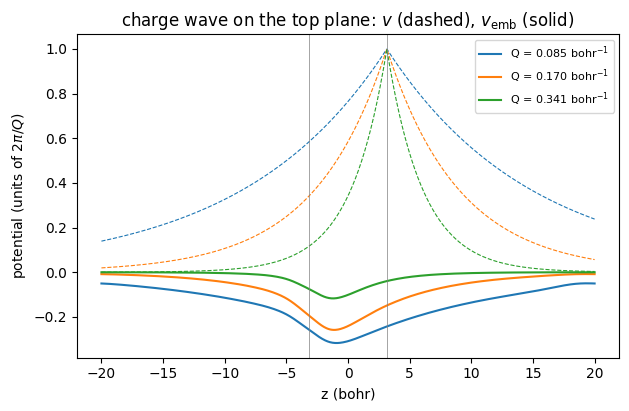

In [5]:
z = np.linspace(-c / 2, c / 2, 801)
fig, ax = plt.subplots(figsize=(7, 4.2))
for iq in [2, 3, 5]:
    Q = np.linalg.norm(q[iq - 1, :2])
    Xb = read_X(screening['ML_bot'], iq)[0][0]
    vemb = along_z(Xb, iq, zero, z, z_top).real * Q / (2 * np.pi)
    l, = ax.plot(z, vemb, label='Q = %.3f bohr$^{-1}$' % Q)
    ax.plot(z, np.exp(-Q * abs(z - z_top)), '--', color=l.get_color(), lw=0.8)
    print('Q = %.3f bohr^-1: on the top plane v_emb/v = %.3f' % (Q, np.interp(z_top, z, vemb)))
for zz in (z_bot, z_top):
    ax.axvline(zz, color='gray', lw=0.5)
ax.set_xlabel('z (bohr)')
ax.set_ylabel('potential (units of $2\\pi/Q$)')
ax.set_title('charge wave on the top plane: $v$ (dashed), $v_{\\rm emb}$ (solid)')
ax.legend(fontsize=8)
plt.show()

- $v$ (dashed) is peaked on the top plane and decays as $e^{-Q|z - z_t|}$: the smaller $Q$, the farther it reaches,
  so the more it polarizes the bottom layer.
- $v_{\mathrm{emb}}$ (solid) is negative (the substrate weakens the interaction), largest at the bottom layer, and above
  it decays as $e^{-Qz}$, the form of Eq. (24). The slab cutoff (interaction truncated at $|z - z'| > c/2 = 20$
  bohr) does not change it in the region of the two layers.
- On the top plane $\tilde v = v + v_{\mathrm{emb}}$ is reduced by 24%, 15% and 4% at these three $Q$.

**$v$ and $\tilde v$ on the top plane, and $g(Q)$**, for all the $\mathbf Q = \mathbf q + \mathbf G_\parallel$ of the
grid and of the block, static and at $i\,27$ eV; $g$ from $\tilde v/v = 1 - g\,e^{-2Qd}$ ($z_0 = 0$, $d = 3.146$
bohr). The factorized form of Eq. (24) is checked by extracting $g$ at different heights $h$ ($z = z' = h$).

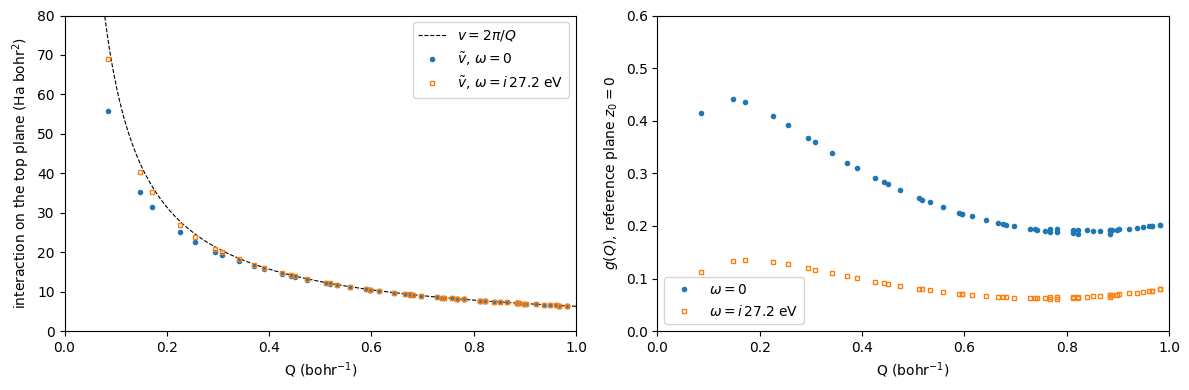

Q (bohr^-1)            0.085  0.148  0.170  0.225  0.256  0.295
v (Ha bohr^2)          73.76  42.59  36.88  27.88  24.59  21.29
vt, w = 0               55.84  35.17  31.39  25.12  22.66  20.08
g,  w = 0               0.415  0.441  0.435  0.409  0.391  0.366
vt, w = i 27 eV         68.88  40.33  35.17  26.99  23.96  20.90
g,  w = i 27 eV         0.113  0.134  0.135  0.131  0.127  0.119
Eq. (24): g extracted at h = 2, 3.15, 5, 8 bohr agrees within 3.2% (8 smallest Q)


In [6]:
vt_rows = []                                             # (iq, Q, vt/v at w = 0, vt/v at i 27 eV)
for iq in range(2, nq + 1):
    Xb = read_X(screening['ML_bot'], iq)[0]
    for idx in blocks.values():
        if len(idx) >= 15:
            Q = np.linalg.norm(q[iq - 1, :2] + G[idx[0], :2])
            vt_rows.append((iq, Q, 1 + on_top_plane(Xb[0], iq, idx), 1 + on_top_plane(Xb[1], iq, idx)))
vt_rows = np.array(vt_rows)
Qs = vt_rows[:, 1]
d = z_top - z_ref
g_rows = (1 - vt_rows[:, 2:]) * np.exp(2 * Qs[:, None] * d)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
Qline = np.linspace(0.06, 1.0, 200)
ax[0].plot(Qline, 2 * np.pi / Qline, 'k--', lw=0.8, label='$v = 2\\pi/Q$')
for iw, (mk, wl) in enumerate([('o', r'$\omega = 0$'), ('s', r'$\omega = i\,27.2$ eV')]):
    kw = dict(ms=3) if iw == 0 else dict(ms=3, mfc='none')
    ax[0].plot(Qs, 2 * np.pi / Qs * vt_rows[:, 2 + iw], mk, label=r'$\tilde v$, ' + wl, **kw)
    ax[1].plot(Qs, g_rows[:, iw], mk, label=wl, **kw)
ax[0].set_ylabel('interaction on the top plane (Ha bohr$^2$)')
ax[0].set_ylim(0, 80)
ax[1].set_ylabel(r'$g(Q)$, reference plane $z_0 = 0$')
ax[1].set_ylim(0, 0.6)
for a in ax:
    a.set_xlim(0, 1.0)
    a.set_xlabel('Q (bohr$^{-1}$)')
    a.legend()
plt.tight_layout()
plt.show()

first = np.argsort(Qs)[:6]
print('Q (bohr^-1)          ' + ''.join('%7.3f' % x for x in Qs[first]))
print('v (Ha bohr^2)        ' + ''.join('%7.2f' % (2 * np.pi / x) for x in Qs[first]))
for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
    print('vt, %-12s      ' % wl + ''.join('%7.2f' % x for x in (2 * np.pi / Qs * vt_rows[:, 2 + iw])[first]))
    print('g,  %-12s      ' % wl + ''.join('%7.3f' % x for x in g_rows[first, iw]))

hs = [2.0, z_top, 5.0, 8.0]
spread = []
for iq in sorted(range(2, nq + 1), key=lambda i: np.linalg.norm(q[i - 1]))[:8]:
    Q = np.linalg.norm(q[iq - 1, :2])
    Xb = read_X(screening['ML_bot'], iq)[0][0]
    gs = np.array([-(Q / (2 * np.pi)) * along_z(Xb, iq, zero, h, h)[0].real * np.exp(2 * Q * (h - z_ref)) for h in hs])
    spread.append((gs.max() - gs.min()) / gs.max())
print('Eq. (24): g extracted at h = 2, %.2f, 5, 8 bohr agrees within %.1f%% (8 smallest Q)' % (z_top, 100 * max(spread)))

- The substrate weakens the interaction on the top plane only at long wavelengths: $\tilde v$ is below $v$ by 24% at
  the smallest $Q$ of the grid (0.085 bohr$^{-1}$), by 10% at $Q \approx 0.22$, and by less than 1% above
  $Q \approx 0.5$. At $\omega = i\,27$ eV the effect is about three times smaller: the substrate response is dynamical.
- All of it is in the single function $g(Q, \omega)$ of Sec. 2.2: above the bottom layer $v_{\mathrm{emb}}$ has the
  factorized form of Eq. (24) ($g$ independent of the height), and the points from different
  $\mathbf q + \mathbf G_\parallel$ fall on one curve (Eq. (21)). Static $g \approx 0.4$ at long wavelengths, decreasing
  at larger $Q$; it must vanish as $Q \to 0$ (a thin substrate does not screen at long wavelengths), below the
  smallest $Q$ of the k = 18 grid.

**The same in real space.** A unit point charge on the top plane. On the plane the laterally averaged
$v_{\mathrm{emb}}$ depends only on the in-plane distance $\rho$, and Eq. (24) gives its Fourier transform in the plane,
a Hankel transform (a.u.):
$$
v_{\mathrm{emb}}(\rho) = \int\frac{d^2Q}{(2\pi)^2}\,e^{i\mathbf Q\cdot\boldsymbol\rho}\,v_{\mathrm{emb}}(Q; z_t, z_t)
= -\int_0^\infty dQ\; g(Q)\,e^{-2Qd}\,J_0(Q\rho) ,
\qquad \tilde v(\rho) = \frac{1}{\rho} + v_{\mathrm{emb}}(\rho) .
$$
For a dielectric half-space ($g = \beta$) it is the image potential of Eq. (26), $-\beta/\sqrt{\rho^2 + 4d^2}$. Which atom
is the source matters only through its height (the registry is in the $\mathbf G_\parallel \ne \mathbf G_\parallel'$
terms). The grid gives $g$ only for $Q \ge Q_{\min} = 0.085$ bohr$^{-1}$; below, the line uses a polarizable sheet,
$g = r_0Q/(1 + r_0Q)\,e^{-2Q\delta}$, fitted on $Q < 0.5$ bohr$^{-1}$, and the band goes from $g$ linear to 0 to $g$
constant: it shows the weight of the region the grid does not sample.

w = 0       sheet fit: r0 = 11.9 bohr, delta = 1.25 bohr; v_emb(0) = -1.43 eV (band -1.32 to -1.72); from Q < Q_min: 32%


w = i 27 eV sheet fit: r0 = 2.0 bohr, delta = 1.90 bohr; v_emb(0) = -0.41 eV (band -0.39 to -0.50); from Q < Q_min: 26%


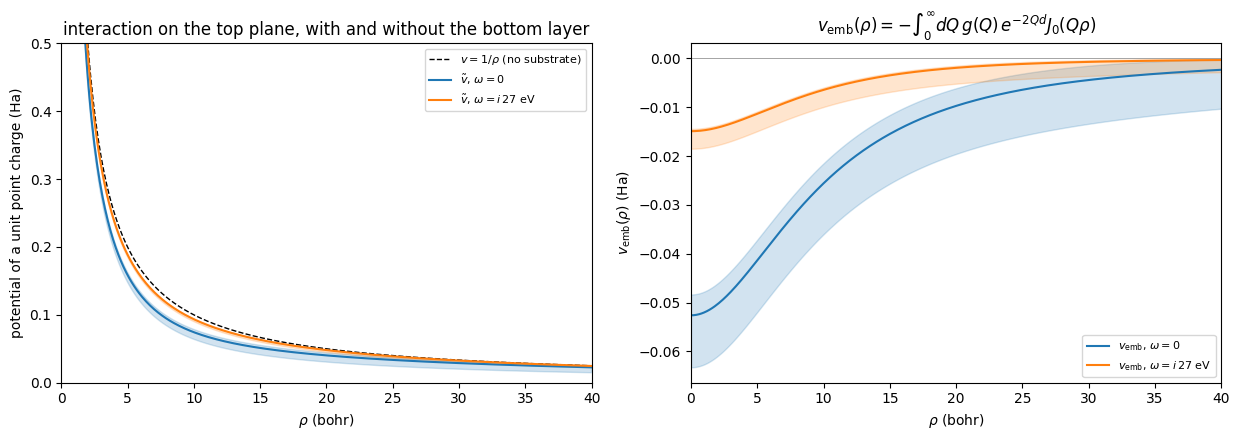

vt/v at rho = 2, 5, 10, 20, 40 bohr (w = 0): 0.90, 0.79, 0.74, 0.81, 0.91
vt/v at rho = 2, 5, 10, 20, 40 bohr (w = i 27 eV): 0.97, 0.94, 0.94, 0.96, 0.99


In [7]:
from scipy.special import j0
from scipy.optimize import curve_fit

def sheet(Q, r0, delta):
    "Polarizable sheet at the depth delta below the reference plane."
    return r0 * Q / (1 + r0 * Q) * np.exp(-2 * Q * delta)

Qf = np.linspace(0, 3.0, 30001)
rho = np.linspace(0, 40, 401)
vemb_rho = {}
for iw in range(2):
    keep = Qs <= 1.0                                     # beyond, e^{-2Qd} < 2e-3 and g is noisy
    Qu = np.unique(np.round(Qs[keep], 4))
    gu = np.array([g_rows[keep, iw][np.round(Qs[keep], 4) == x].mean() for x in Qu])
    fit = curve_fit(sheet, Qu[Qu < 0.5], gu[Qu < 0.5], p0=(10, 1))[0]
    low = Qf < Qu[0]
    for name in ('sheet', 'linear', 'constant'):
        gm = np.interp(Qf, Qu, gu)
        gm[low] = {'sheet': sheet(Qf[low], *fit), 'linear': gu[0] * Qf[low] / Qu[0], 'constant': gu[0]}[name]
        w = gm * np.exp(-2 * Qf * d)
        vemb_rho[iw, name] = -np.trapezoid(w[None, :] * j0(np.outer(rho, Qf)), Qf, axis=1)
        if name == 'sheet':
            share = np.trapezoid(w[low], Qf[low]) / np.trapezoid(w, Qf)
    print('%-11s sheet fit: r0 = %.1f bohr, delta = %.2f bohr; v_emb(0) = %.2f eV (band %.2f to %.2f); '
          'from Q < Q_min: %.0f%%' % ('w = 0' if iw == 0 else 'w = i 27 eV', *fit, vemb_rho[iw, 'sheet'][0] * HaToeV,
          vemb_rho[iw, 'linear'][0] * HaToeV, vemb_rho[iw, 'constant'][0] * HaToeV, 100 * share))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
sel = rho >= 1.0
ax[0].plot(rho[sel], 1 / rho[sel], 'k--', lw=1, label=r'$v = 1/\rho$ (no substrate)')
for iw, col, lab in ((0, 'C0', r'$\omega = 0$'), (1, 'C1', r'$\omega = i\,27$ eV')):
    ax[0].plot(rho[sel], 1 / rho[sel] + vemb_rho[iw, 'sheet'][sel], color=col, label=r'$\tilde v$, ' + lab)
    ax[0].fill_between(rho[sel], 1 / rho[sel] + vemb_rho[iw, 'linear'][sel], 1 / rho[sel] + vemb_rho[iw, 'constant'][sel],
                       color=col, alpha=0.2)
    ax[1].plot(rho, vemb_rho[iw, 'sheet'], color=col, label=r'$v_{\rm emb}$, ' + lab)
    ax[1].fill_between(rho, vemb_rho[iw, 'linear'], vemb_rho[iw, 'constant'], color=col, alpha=0.2)
ax[0].set_ylim(0, 0.5)
ax[0].set_ylabel('potential of a unit point charge (Ha)')
ax[0].set_title('interaction on the top plane, with and without the bottom layer')
ax[1].axhline(0, color='gray', lw=0.5)
ax[1].set_ylabel(r'$v_{\rm emb}(\rho)$ (Ha)')
ax[1].set_title(r'$v_{\rm emb}(\rho) = -\int_0^\infty dQ\, g(Q)\, e^{-2Qd} J_0(Q\rho)$')
for a in ax:
    a.set_xlim(0, 40)
    a.set_xlabel(r'$\rho$ (bohr)')
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()
for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
    print('vt/v at rho = 2, 5, 10, 20, 40 bohr (%s): ' % wl +
          ', '.join('%.2f' % (1 + x * np.interp(x, rho, vemb_rho[iw, 'sheet'])) for x in (2, 5, 10, 20, 40)))

- $\tilde v$ is below $1/\rho$ by up to about 25%, around $\rho \approx 10$ bohr; it goes back to $1/\rho$ at short
  distances, where $1/\rho$ dominates, and at large distances, since a thin substrate does not screen there ($g \to 0$
  as $Q \to 0$). At $\omega = i\,27$ eV the effect is about four times smaller.
- $v_{\mathrm{emb}}(0) \approx -1.4$ eV (static) is the potential that the charge feels from its own image in the bottom
  layer. A quarter to 40% of it comes from $Q < Q_{\min}$, so the real-space values are indicative: a denser grid,
  or a treatment of the small-$Q$ region as the RIM does, is needed to make them quantitative. The sheet fit puts
  the induced charge at $z \approx -1.25$ bohr ($\delta$ below $z_0 = 0$), close to the lobe seen above.
- This is not the GW correction: in $W$ the effect of the substrate is screened in turn by the layer itself
  (Sec. 4).

## 4. $W$ of the top layer with the substrate

Eq. (19) in the symmetrized form ($\tilde W = v^{-1/2}Wv^{-1/2}$, $\tilde{\tilde v} = v^{-1/2}\tilde v v^{-1/2} = 1 +
X^{\mathrm S}$, $\tilde\chi_0^{\mathrm L} = 1 - (1 + X^{\mathrm L})^{-1}$):
$$
\tilde W = \left(1 - \tilde{\tilde v}\,\tilde\chi_0^{\mathrm L}\right)^{-1}\tilde{\tilde v} ,
\qquad X^{\mathrm{new}} = \tilde W - 1 = \varepsilon^{-1}_{\mathrm{eff}} - 1 ,
$$
at each $\mathbf q$ and frequency. It needs $\chi^{\mathrm S}$ of the substrate (stored) and $\chi_0^{\mathrm L}$ of the
layer (from its $X$). Both come from the database of `ML_bot` only: $X^{\mathrm S}$ as read, $X^{\mathrm L}$ = the same
$X$ moved onto the top layer (Sec. 2). The same $W$ follows from $\tilde W = (1 - \tilde\chi_0^{\mathrm S} - \tilde\chi_0^{\mathrm L})^{-1}$
(additive $\chi_0$, Eqs. (16)-(17) of the notes): used as a check of the algebra. The physical check is the comparison with the
$X$ of the explicit bilayer, which differs only by the hybridization of the states in $\chi_0$.

$X^{\mathrm{new}}$ is written as a new screening database of the top layer, in a new folder of its run,
`ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot`: the files of the `ML_top` database are used only as a template (header
and netCDF layout of the run that will read it), and `X_Q` is replaced by $X^{\mathrm{new}}$; no `ndb.RIM_W` (Yambo
recomputes it from the new $X$). The original databases are not touched. A fragment already on disk is rewritten only
if its content differs from $X^{\mathrm{new}}$ by more than the single-precision round-off.

In [8]:
I = np.eye(ng)

def embed(X_layer, X_sub):
    "X of the layer screened by the substrate, Eq. (19) of the notes in symmetrized form."
    vt = I + X_sub
    chi0_layer = I - np.linalg.inv(I + X_layer)
    return np.linalg.solve(I - vt @ chi0_layer, vt) - I

def write_fragment(src, dst, iq, X):
    "Copy the fragment iq of the database src into dst and replace X_Q (array [frequency, G, G'])."
    name = 'ndb.pp_fragment_%d' % iq
    shutil.copy2(os.path.join(src, name), os.path.join(dst, name))
    with Dataset(os.path.join(dst, name), 'r+') as f:
        x = np.transpose(X, (0, 2, 1))
        f['X_Q_%d' % iq][:] = np.stack([x.real, x.imag], axis=-1).astype(np.float32)

new_db = {bl: os.path.join(MB, run['ML_top_' + bl], 'ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot') for bl in names}
for bl in names:
    if not os.path.isdir(new_db[bl]):
        os.makedirs(new_db[bl])
    if not os.path.isfile(os.path.join(new_db[bl], 'ndb.pp')):
        shutil.copy2(os.path.join(screening['ML_top_' + bl], 'ndb.pp'), new_db[bl])

W_rows, checks, rewritten = [], [], {bl: 0 for bl in names}
for iq in range(1, nq + 1):
    Xb = read_X(screening['ML_bot'], iq)[0]
    for bl in names:
        Xt = move_layer(Xb, iq, operation[bl], tau[bl])                 # top layer from the bottom one (Sec. 2)
        Xbl = read_X(screening[bl], iq)[0]
        Xnew = np.array([embed(Xt[iw], Xb[iw]) for iw in range(2)])
        frag = os.path.join(new_db[bl], 'ndb.pp_fragment_%d' % iq)
        if not os.path.isfile(frag) or abs(read_X(new_db[bl], iq)[0] - Xnew).max() > 1e-7:
            write_fragment(screening['ML_top_' + bl], new_db[bl], iq, Xnew)
            rewritten[bl] += 1
        Xdisk = read_X(new_db[bl], iq)[0]
        Xrun = read_X(screening['ML_top_' + bl], iq)[0]                  # check only: the computed top layer
        for iw in range(2):
            Xsum = np.linalg.inv(np.linalg.inv(I + Xt[iw]) + np.linalg.inv(I + Xb[iw]) - I) - I
            Xnew_run = embed(Xrun[iw], Xb[iw])
            checks.append((bl, iq, iw, abs(Xnew[iw] - Xsum).max(), abs(Xdisk[iw] - Xnew[iw]).max(),
                           np.linalg.norm(Xnew[iw] - Xbl[iw]) / np.linalg.norm(Xbl[iw]),
                           np.linalg.norm(Xt[iw] - Xbl[iw]) / np.linalg.norm(Xbl[iw]),
                           np.linalg.norm(Xnew[iw] - Xnew_run) / np.linalg.norm(Xnew_run)))
        if iq > 1:
            for idx in blocks.values():
                if len(idx) >= 15:
                    Q = np.linalg.norm(q[iq - 1, :2] + G[idx[0], :2])
                    W_rows.append((bl, iq, Q) + tuple(1 + on_top_plane(M[iw], iq, idx) for M in (Xt, Xnew, Xbl)
                                                     for iw in range(2)))

chk = np.array([r[3:] for r in checks])
for bl in names:
    print('%-3s %s: %d of %d fragments written in this execution' % (names[bl], new_db[bl], rewritten[bl], nq))
print('Eq. (19) vs additive chi0, max |dX|: %.1e' % chk[:, 0].max())
print('written vs computed (single precision), max |dX|: %.1e' % chk[:, 1].max())
q0 = np.array([r[1] == 1 for r in checks])
print('X_new from ML_bot only vs X_new with the computed ML_top database: ||dX|| / ||X|| = %.1e at q -> 0, <= %.1e at the other q'
      % (chk[q0, 4].max(), chk[~q0, 4].max()))
for bl in names:
    for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
        m = np.array([(r[0] == bl and r[2] == iw) for r in checks])
        print('%-3s %-11s ||X - X_bilayer|| / ||X_bilayer||: effective %.3f-%.3f, top layer alone %.3f-%.3f' % (
              names[bl], wl, chk[m, 2].min(), chk[m, 2].max(), chk[m, 3].min(), chk[m, 3].max()))

AA' MB_analysis/kpoints_18-nbnds_250-ML_top_AA1/ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot: 0 of 37 fragments written in this execution
AB  MB_analysis/kpoints_18-nbnds_250-ML_top_AB/ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot: 0 of 37 fragments written in this execution
Eq. (19) vs additive chi0, max |dX|: 2.3e-15
written vs computed (single precision), max |dX|: 1.5e-08
X_new from ML_bot only vs X_new with the computed ML_top database: ||dX|| / ||X|| = 1.2e-04 at q -> 0, <= 1.4e-05 at the other q
AA' w = 0       ||X - X_bilayer|| / ||X_bilayer||: effective 0.004-0.023, top layer alone 0.684-0.706
AA' w = i 27 eV ||X - X_bilayer|| / ||X_bilayer||: effective 0.002-0.003, top layer alone 0.699-0.706
AB  w = 0       ||X - X_bilayer|| / ||X_bilayer||: effective 0.003-0.020, top layer alone 0.684-0.706
AB  w = i 27 eV ||X - X_bilayer|| / ||X_bilayer||: effective 0.002-0.003, top layer alone 0.699-0.706


**$W$ on the plane of the top layer** ($W/v$, laterally averaged as in Sec. 3): the top layer alone, with the
substrate (effective) and in the explicit bilayer.

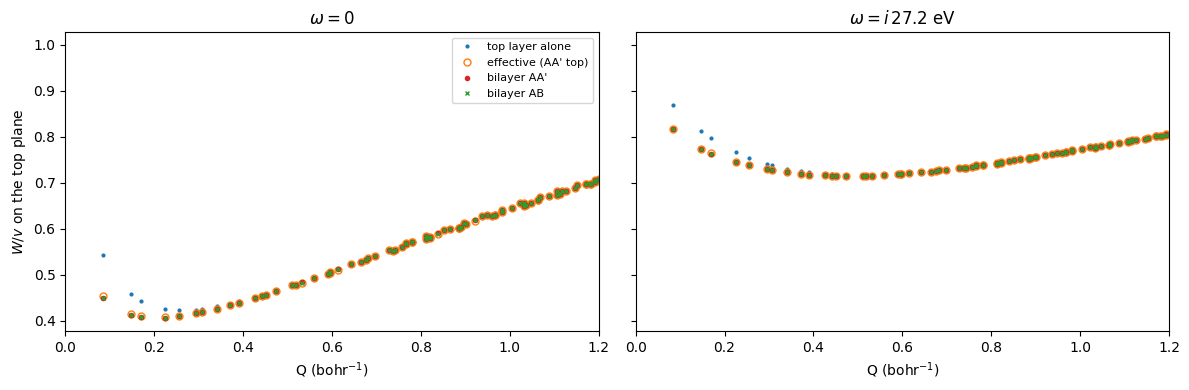

AA' w = 0       max |effective - bilayer| = 0.0034, max |alone - bilayer| = 0.0929 (units of v)
AA' w = i 27 eV max |effective - bilayer| = 0.0002, max |alone - bilayer| = 0.0542 (units of v)
AB  w = 0       max |effective - bilayer| = 0.0035, max |alone - bilayer| = 0.0929 (units of v)
AB  w = i 27 eV max |effective - bilayer| = 0.0003, max |alone - bilayer| = 0.0542 (units of v)


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for iw, wl in enumerate([r'$\omega = 0$', r'$\omega = i\,27.2$ eV']):
    for bl, mk in [('AA1', 'o'), ('AB', 'x')]:
        r = np.array([row[2:] for row in W_rows if row[0] == bl])
        if bl == 'AA1':
            ax[iw].plot(r[:, 0], r[:, 1 + iw], '.', color='C0', ms=4, label='top layer alone')
            ax[iw].plot(r[:, 0], r[:, 3 + iw], 'o', color='C1', ms=5, mfc='none', label="effective (AA' top)")
        ax[iw].plot(r[:, 0], r[:, 5 + iw], mk, color='C3' if bl == 'AA1' else 'C2', ms=3, label='bilayer ' + names[bl])
    ax[iw].set_title(wl)
    ax[iw].set_xlabel('Q (bohr$^{-1}$)')
    ax[iw].set_xlim(0, 1.2)
ax[0].set_ylabel('$W / v$ on the top plane')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
for bl in names:
    r = np.array([row[2:] for row in W_rows if row[0] == bl])
    for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
        print('%-3s %-11s max |effective - bilayer| = %.4f, max |alone - bilayer| = %.4f (units of v)' % (
              names[bl], wl, abs(r[:, 3 + iw] - r[:, 5 + iw]).max(), abs(r[:, 1 + iw] - r[:, 5 + iw]).max()))

- Eq. (19) and the additive form give the same $X$ (round-off), and the database on disk is the computed one within
  single precision. Built from `ML_bot` alone, $X^{\mathrm{new}}$ equals the one obtained with the computed `ML_top`
  database at the level of Sec. 2 ($\sim 10^{-5}$, $10^{-4}$ at $\mathbf q \to 0$).
- The effective $W$ is the $W$ of the explicit bilayer: on the top plane within 0.004 $v$ ($\omega = 0$) and 0.0003
  $v$ ($i\,27$ eV), against a substrate effect of up to 0.09 $v$ (the layer alone). The full matrices agree within
  0.3-2.3% (largest at $q \to 0$), against about 70% for the layer alone. The two stackings give the same effective $W$ on
  the plane, as expected (the registry enters only the $\mathbf G_\parallel \ne \mathbf G_\parallel'$ terms).
- So in this benchmark the screening is not the issue: the hybridization of the states, which the effective scheme
  does not have, barely changes $\chi_0$. The differences between the effective and the explicit GW will come from the
  states (the Green's function), not from $W$.

## 5. Next: GW of the top layer with the new database

To run (after agreeing with the user): the GW of `ML_top_AA1` and `ML_top_AB` with the converged parameters and the
input of their runs, with `ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot` in place of the original screening folder in
the `jobname` list, and no `ndb.RIM_W` from earlier runs (recomputed). First at the checked points ($\Gamma$, K), then
on the full IBZ; then the GW corrections of the top layer, effective vs extracted from the bilayer
(`results/layer_projection.json`).